# 06 · Multi-level OFI and Hawkes processes (Day 4: Stages 7 and 9)
**Microstructure Alpha · development days only (D1–D5), walk-forward by day**

| Part | Content | Hypothesis |
|---|---|---|
| A | **Model ladder** at every horizon where notebook 05 found significant prediction: zero · empirical microprice · level-1 OFI · levels 1..L (L = 2..10) · ridge · lasso · integrated OFI (PC1) · OFI / touch depth · OFI + microprice. Level-inclusion rule with block-bootstrap CIs | **H5** |
| B1 | **Taker-order Hawkes** (buy/sell streams): exponential vs two-exponential vs 12-exponential multi-scale kernels by held-out likelihood and time-rescaling; hourly branching ratio; jitter sensitivity for same-millisecond ties | — |
| B2 | **Six-stream Hawkes**: buy/sell taker orders + bid/ask adds and cancels at the touch; excitation matrix with CIs, read economically | — |
| B3 | **Do Hawkes intensities add OOS R² beyond OFI?** | **H7** |

**Decision rules (written before running).**
- **H5:** candidates are levels 1–10 (OLS), ridge, lasso and integrated OFI. H5 is supported if, at some horizon, a candidate beats **both** level-1 OFI and the microprice in a Diebold–Mariano test, Holm-adjusted across the whole candidates × baselines × horizons family at 5%. A level is kept only while its marginal OOS R² gain has a 95% block-bootstrap CI above 0 (sequentially from level 2).
- **H7:** OFI1 + Hawkes excitation features vs OFI1 alone, DM test. Supported if Holm-adjusted p < 0.05 at some horizon.
- Ridge and lasso penalties are chosen on the last training day of each fold. Integrated-OFI loadings, microprice bins, standardisation constants and Hawkes parameters are fit on training days only.

**Hawkes estimation.** EM for multivariate Hawkes with fixed decay rates (exact, numba), checked first on simulated data. The "power-law" family is a 12-exponential multi-scale kernel with geometric rates from 0.1 to 1000 s⁻¹, which can represent power-law decay. The branching ratio is the spectral radius of the integrated excitation matrix. A constant baseline is fitted per hour; intraday intensity changes within an hour bias branching ratios upward, so they are an upper bound.

**Runtime:** about 45–90 minutes. **Memory:** close the kernels of notebooks 01–05 first (each can hold several GB); this notebook needs about 2–3 GB free.

In [1]:
# ===================== CONFIG =====================
from pathlib import Path
OUT_DIR       = Path(r"C:\microalpha_proj\microoutput")
BOOT_REPS     = 1000
EM_ITERS      = 150
EXP_BETAS     = [1, 3, 10, 30, 100, 300]          # s^-1 grid for exponential kernels
KERNEL_HOURS  = [0, 4, 8, 12, 16, 20]             # hours per day used for the kernel comparison (held-out = next hour)
SIX_HOURS     = [6, 14]                           # hours per day for the six-stream model (quiet Asia / busy US open)
JITTER_SEEDS  = [1, 2, 3]
STRICT        = True
# ==================================================

In [2]:
import sys, time, math, itertools, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd()))
import ma_lib
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60)
P = ma_lib.load_protocol(OUT_DIR)
REP, EVT, FEA = OUT_DIR / 'reports', OUT_DIR / 'events', OUT_DIR / 'features'
DEV = [d for d in P['data_split']['development'] if (FEA / 'ex' / f'feat_ex_{d}.parquet').exists()]
BIN_S = P['grid']['bin_ms'] / 1000; EMB_MIN = P['purge_embargo']['embargo_minutes']; SEED = P['inference']['seed']; BLOCK_MIN = P['inference']['bootstrap']['block_minutes']
hz05 = pd.read_csv(REP / '05_horizon_curve.csv')
H5_HORIZONS = [float(h) for h in hz05.loc[hz05.rw_p < 0.05, 'h_s']]
print('protocol OK | development days:', DEV, '| horizons from notebook 05 (RW-significant):', H5_HORIZONS)
if STRICT and len(DEV) != 5: raise RuntimeError('all 5 development days are required')
FOLDS = [(DEV[:i], DEV[i]) for i in range(1, len(DEV))]
def emb_mask(t_end, day):
    t0 = pd.Timestamp(day).value // 10**6; return (t_end >= t0 + EMB_MIN * 60_000) & (t_end <= t0 + 86_400_000 - EMB_MIN * 60_000)
GCOLS = ['t_end', 'valid', 'bp1', 'ap1', 'bq1', 'aq1'] + [f'ofi{l}' for l in range(1, 11)]
import gc
def load_grid(d):                                   # compact dtypes: ~4x less memory than the stored int64 columns
    g = pd.read_parquet(FEA / 'ex' / f'feat_ex_{d}.parquet', columns=GCOLS)
    for c in GCOLS:
        if c.startswith('ofi') or c in ('bq1', 'aq1'): g[c] = g[c].astype(np.float32)
        elif c in ('bp1', 'ap1'): g[c] = g[c].astype(np.int32)
    gc.collect(); return g
GRID = {}
for d in DEV:
    GRID[d] = load_grid(d)
print('feature grids loaded:', {d: f'{g.memory_usage(deep=True).sum() / 2**20:.0f} MB' for d, g in GRID.items()})

protocol OK | development days: ['2026-09-07', '2026-09-08', '2026-09-09', '2026-09-10', '2026-09-11'] | horizons from notebook 05 (RW-significant): [0.1, 0.25, 0.5, 1.0, 5.0, 30.0]
feature grids loaded: {'2026-09-07': '54 MB', '2026-09-08': '54 MB', '2026-09-09': '54 MB', '2026-09-10': '54 MB', '2026-09-11': '54 MB'}


## A · Multi-level OFI model ladder (H5)
Each horizon *h* uses non-overlapping buckets of length *h*. Features describe the current bucket (OFI per level, plus queue imbalance and depth at its end) and the target is the mid change over the **next** bucket. Models are fit per fold on training days and scored on the held-out day. OOS R² is measured against the zero forecast.

In [3]:
LV = [f'ofi{l}' for l in range(1, 11)]
def day_data(d, k):
    b = ma_lib.bucket_levels(GRID[d], k)
    y = b.dp.shift(-1); m = b.valid & b.valid.shift(-1, fill_value=False) & emb_mask(b.t_end, d) & np.isfinite(b.qi_end) & (b.depth_end > 0)
    b = b[m]
    return dict(X=b[LV].to_numpy(np.float32), qi=b.qi_end.to_numpy(np.float32), dep=b.depth_end.to_numpy(np.float32),
                y=y[m].to_numpy(np.float64), t=b.t_end.to_numpy())
def gram(Z, y, chunk=400_000):
    # Z'Z and Z'y accumulated in float64 over row chunks (Z may be float32 and large)
    p = Z.shape[1]; G = np.zeros((p, p)); g = np.zeros(p)
    for i in range(0, len(y), chunk):
        z = Z[i:i + chunk].astype(np.float64); G += z.T @ z; g += z.T @ y[i:i + chunk]
    return G, g
def fit_small(Z, y):                                 # OLS with intercept for 1–3 regressors (small memory)
    Zc = np.c_[np.ones(len(y)), Z]; return np.linalg.solve(Zc.T @ Zc, Zc.T @ y)
ols_fit = fit_small
def ols_pred(coef, Z):
    Z = np.asarray(Z); return coef[0] + (Z @ coef[1:] if Z.ndim > 1 else Z * coef[1])
ALPHAS = np.logspace(-2, 5, 15); LAMS = np.logspace(-6, -1, 11)
MODELS = ['zero', 'microprice'] + [f'levels_1_{L}' for L in range(1, 11)] + ['ridge', 'lasso', 'integrated_pc1', 'ofi1_over_depth', 'ofi1_plus_micro']
ladder_rows, dm_rows, incl_rows, coef_rows = [], [], [], []
for h in H5_HORIZONS:
    t0 = time.time(); k = max(1, int(round(h / BIN_S)))
    D = {d: day_data(d, k) for d in DEV}
    SQE = {m: [] for m in MODELS}; ys, ts = [], []          # store squared errors (float32), not predictions
    for tr_days, te in FOLDS:
        Str = np.concatenate([D[d]['X'] for d in tr_days]); ytr = np.concatenate([D[d]['y'] for d in tr_days])
        qtr = np.concatenate([D[d]['qi'] for d in tr_days]); dtr = np.concatenate([D[d]['dep'] for d in tr_days])
        raw1_tr = Str[:, 0].copy()
        mu_, sd_ = Str.mean(0, dtype=np.float64), Str.std(0, dtype=np.float64); sd_[sd_ == 0] = 1
        Str -= mu_.astype(np.float32); Str /= sd_.astype(np.float32)                      # standardize in place
        Xte, yte, qte, dte = D[te]['X'], D[te]['y'], D[te]['qi'], D[te]['dep']
        Ste = ((Xte - mu_) / sd_).astype(np.float32)
        ym = ytr.mean(); yc = ytr - ym; n = len(ytr)
        G, g = gram(Str, yc)
        ys.append(yte); ts.append(D[te]['t'])
        def put(m, pred): SQE[m].append(((yte - pred) ** 2).astype(np.float32))
        put('zero', np.zeros_like(yte))
        edges = np.unique(np.quantile(qtr, np.linspace(0, 1, 11))); edges[0], edges[-1] = -np.inf, np.inf
        bt, be = np.digitize(qtr, edges[1:-1]), np.digitize(qte, edges[1:-1])
        cm = np.bincount(bt, weights=ytr, minlength=len(edges) - 1) / np.maximum(np.bincount(bt, minlength=len(edges) - 1), 1)
        micro_tr, micro_te = cm[bt], cm[be]; put('microprice', micro_te)
        for L in range(1, 11):                                                            # centered OLS via the Gram matrix
            bL = np.linalg.solve(G[:L, :L], g[:L]); put(f'levels_1_{L}', ym + Ste[:, :L].astype(np.float64) @ bL)
        if len(tr_days) >= 2:
            ni = sum(len(D[d]['y']) for d in tr_days[:-1]); yi = ytr[:ni]
            Gi, gi = gram(Str[:ni], yi - yi.mean()); Sv = Str[ni:].astype(np.float64); yv = ytr[ni:]
            a_best = min(ALPHAS, key=lambda a: np.mean((yv - yi.mean() - Sv @ ma_lib.ridge_gram(Gi, gi, a)) ** 2))
            l_best = min(LAMS, key=lambda l: np.mean((yv - yi.mean() - Sv @ ma_lib.lasso_gram(Gi, gi, ni, l)) ** 2))
            del Sv
        else:
            a_best, l_best = 10.0, 1e-4
        br = ma_lib.ridge_gram(G, g, a_best); bl = ma_lib.lasso_gram(G, g, n, l_best)
        S64 = Ste.astype(np.float64)
        put('ridge', ym + S64 @ br); put('lasso', ym + S64 @ bl)
        coef_rows.append(dict(h_s=h, test_day=te, ridge_alpha=a_best, lasso_lambda=l_best,
                              **{f'ridge_l{l+1}': br[l] for l in range(10)}, **{f'lasso_l{l+1}': bl[l] for l in range(10)}))
        w = np.linalg.eigh(G / n)[1][:, -1]; w = w * np.sign(w[0])                        # PC1 of standardized levels
        ztr = Str.astype(np.float64) @ w if n < 5_000_000 else np.concatenate([Str[i:i+400_000].astype(np.float64) @ w for i in range(0, n, 400_000)])
        c = fit_small(ztr, ytr); put('integrated_pc1', c[0] + (S64 @ w) * c[1]); del ztr
        c = fit_small(raw1_tr / dtr, ytr); put('ofi1_over_depth', c[0] + c[1] * (Xte[:, 0] / dte))
        c = fit_small(np.c_[Str[:, 0], micro_tr], ytr); put('ofi1_plus_micro', c[0] + c[1] * Ste[:, 0] + c[2] * micro_te)
        del Str, ytr, qtr, dtr, raw1_tr, Ste, S64; gc.collect()
    Y = np.concatenate(ys); T_ = np.concatenate(ts); blk = ma_lib.block_ids(T_, BLOCK_MIN); ub, inv = np.unique(blk, return_inverse=True)
    E = {m: np.concatenate(v) for m, v in SQE.items()}; del SQE
    SY2 = (Y ** 2).sum()
    for m in MODELS:
        ladder_rows.append(dict(h_s=h, model=m, oos_r2=1 - E[m].sum(dtype=np.float64) / SY2))
    for cand in ['levels_1_10', 'ridge', 'lasso', 'integrated_pc1']:
        for base in ['levels_1_1', 'microprice']:
            st, p, _ = ma_lib.dm_test(E[base], E[cand], 6); dm_rows.append(dict(h_s=h, candidate=cand, baseline=base, dm_stat=st, p=p))
    SY = np.bincount(inv, weights=Y ** 2); SSE = {L: np.bincount(inv, weights=E[f'levels_1_{L}']) for L in range(1, 11)}
    rngb = np.random.default_rng(SEED); picks = rngb.integers(0, len(ub), (BOOT_REPS, len(ub)))
    keep = True
    for L in range(2, 11):
        gain = (SSE[L - 1].sum() - SSE[L].sum()) / SY.sum()
        boots = (SSE[L - 1][picks].sum(1) - SSE[L][picks].sum(1)) / SY[picks].sum(1)
        lo, hi = np.percentile(boots, [2.5, 97.5]); keep = keep and lo > 0
        incl_rows.append(dict(h_s=h, level=L, marginal_gain=gain, ci_lo=lo, ci_hi=hi, kept=keep))
    r2 = {m: 1 - E[m].sum(dtype=np.float64) / SY2 for m in MODELS}
    print(f'h={h}s: ' + ' | '.join(f"{m} {r2[m]:.5f}" for m in ['microprice', 'levels_1_1', 'levels_1_10', 'ridge', 'lasso', 'integrated_pc1', 'ofi1_plus_micro'])
          + f' | n_test {len(Y):,} | {time.time()-t0:.0f}s')
    del D, E, Y, T_; gc.collect()
lad = pd.DataFrame(ladder_rows).pivot(index='model', columns='h_s', values='oos_r2')
order = ['zero', 'microprice', 'levels_1_1'] + [f'levels_1_{L}' for L in range(2, 11)] + ['ridge', 'lasso', 'integrated_pc1', 'ofi1_over_depth', 'ofi1_plus_micro']
lad = lad.loc[[m for m in order if m in lad.index]]
dmt = pd.DataFrame(dm_rows); inc = pd.DataFrame(incl_rows); coefs = pd.DataFrame(coef_rows)
# Holm across the full family
pv = dmt.p.to_numpy(); o = np.argsort(pv); adj = np.empty_like(pv); run = 0.0
for r, i in enumerate(o): run = max(run, min(1.0, (len(pv) - r) * pv[i])); adj[i] = run
dmt['p_holm'] = adj
win = dmt[dmt.p_holm < 0.05].groupby(['h_s', 'candidate']).baseline.nunique()
H5 = dict(supported=bool((win == 2).any()), winning=[f'{c} @ {h}s' for (h, c), n_ in win.items() if n_ == 2],
          levels_kept={h: int(1 + inc[(inc.h_s == h) & inc.kept].shape[0]) for h in H5_HORIZONS})
print('OOS R² by model and horizon:'); display(lad.style.format('{:.5f}'))
print('Diebold–Mariano (one-sided, candidate better), Holm-adjusted:'); display(dmt.round(5))
print('level inclusion (sequential):'); display(inc.round(6))
print('H5:', H5)
lad.to_csv(REP / '06_h5_ladder.csv'); dmt.to_csv(REP / '06_h5_dm.csv', index=False); inc.to_csv(REP / '06_level_inclusion.csv', index=False); coefs.to_csv(REP / '06_h5_coefs.csv', index=False)

h=0.1s: microprice 0.02477 | levels_1_1 0.01827 | levels_1_10 0.01983 | ridge 0.01983 | lasso 0.01980 | integrated_pc1 0.01490 | ofi1_plus_micro 0.03428 | n_test 3,373,024 | 14s
h=0.25s: microprice 0.02914 | levels_1_1 0.01418 | levels_1_10 0.01432 | ridge 0.01431 | lasso 0.01430 | integrated_pc1 0.00888 | ofi1_plus_micro 0.03411 | n_test 1,686,510 | 5s
h=0.5s: microprice 0.03380 | levels_1_1 0.01197 | levels_1_10 0.01186 | ridge 0.01185 | lasso 0.01185 | integrated_pc1 0.00661 | ofi1_plus_micro 0.03600 | n_test 674,602 | 3s
h=1.0s: microprice 0.03600 | levels_1_1 0.00919 | levels_1_10 0.00916 | ridge 0.00919 | lasso 0.00909 | integrated_pc1 0.00595 | ofi1_plus_micro 0.03655 | n_test 337,300 | 2s
h=5.0s: microprice 0.02527 | levels_1_1 0.00315 | levels_1_10 0.00281 | ridge 0.00247 | lasso 0.00288 | integrated_pc1 0.00180 | ofi1_plus_micro 0.02519 | n_test 67,458 | 1s
h=30.0s: microprice 0.00520 | levels_1_1 0.00072 | levels_1_10 -0.00157 | ridge -0.00065 | lasso -0.00136 | integrated_p

h_s,0.100000,0.250000,0.500000,1.000000,5.000000,30.000000
model,,,,,,
zero,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
microprice,0.02477,0.02914,0.03380,0.03600,0.02527,0.00520
levels_1_1,0.01827,0.01418,0.01197,0.00919,0.00315,0.00072
levels_1_2,0.01882,0.01420,0.01192,0.00919,0.00306,0.00039
levels_1_3,0.01914,0.01421,0.01192,0.00916,0.00302,0.00028
levels_1_4,0.01929,0.01422,0.01187,0.00914,0.00304,0.00052
levels_1_5,0.01941,0.01426,0.01186,0.00910,0.00298,0.00044
levels_1_6,0.01950,0.01428,0.01185,0.00910,0.00294,0.00028
levels_1_7,0.01955,0.01428,0.01184,0.00908,0.00289,0.00021


Diebold–Mariano (one-sided, candidate better), Holm-adjusted:


,h_s,candidate,baseline,dm_stat,p,p_holm
0,0.10,levels_1_10,levels_1_1,11.48155,0.00000,0.00000
1,0.10,levels_1_10,microprice,-13.15125,1.00000,1.00000
2,0.10,ridge,levels_1_1,11.48151,0.00000,0.00000
3,0.10,ridge,microprice,-13.15126,1.00000,1.00000
4,0.10,lasso,levels_1_1,11.90804,0.00000,0.00000
5,0.10,lasso,microprice,-13.63419,1.00000,1.00000
6,0.10,integrated_pc1,levels_1_1,-9.99538,1.00000,1.00000
7,0.10,integrated_pc1,microprice,-22.24152,1.00000,1.00000
8,0.25,levels_1_10,levels_1_1,2.68585,0.00362,0.16278
9,0.25,levels_1_10,microprice,-41.38619,1.00000,1.00000


level inclusion (sequential):


,h_s,level,marginal_gain,ci_lo,ci_hi,kept
0,0.10,2,0.000546,0.000362,0.000744,True
1,0.10,3,0.000325,0.000229,0.000426,True
2,0.10,4,0.000145,0.000036,0.000249,True
3,0.10,5,0.000125,0.000031,0.000210,True
4,0.10,6,0.000087,-0.000055,0.000184,False
5,0.10,7,0.000050,-0.000010,0.000105,False
6,0.10,8,0.000122,0.000048,0.000203,False
7,0.10,9,0.000093,0.000034,0.000154,False
8,0.10,10,0.000069,0.000029,0.000107,False
9,0.25,2,0.000017,-0.000040,0.000072,False


H5: {'supported': False, 'winning': [], 'levels_kept': {0.1: 5, 0.25: 1, 0.5: 1, 1.0: 1, 5.0: 1, 30.0: 1}}


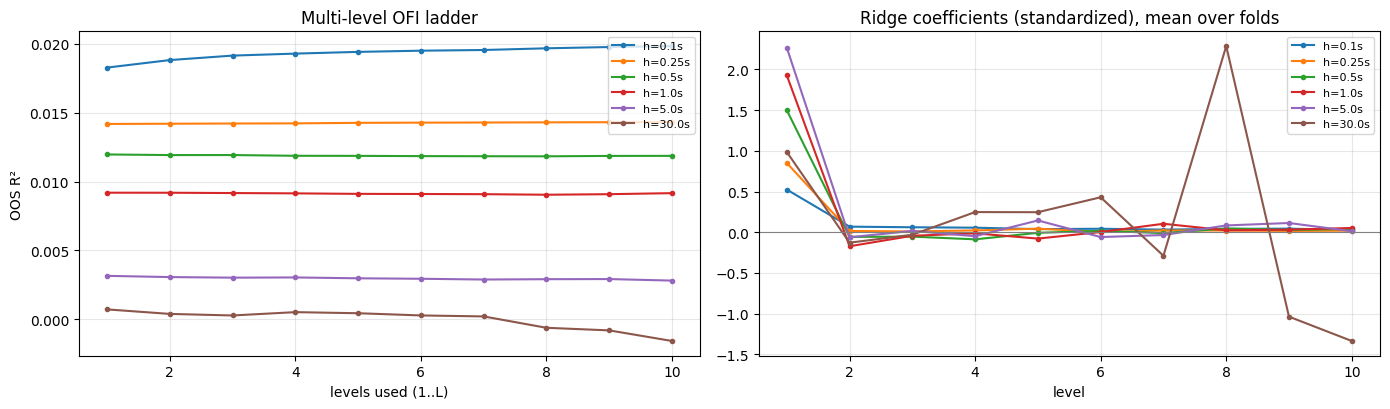

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for h in H5_HORIZONS:
    ax[0].plot(range(1, 11), [lad.loc[f'levels_1_{L}', h] for L in range(1, 11)], 'o-', ms=3, label=f'h={h}s')
ax[0].set_xlabel('levels used (1..L)'); ax[0].set_ylabel('OOS R²'); ax[0].set_title('Multi-level OFI ladder'); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
cm_ = coefs.groupby('h_s')[[f'ridge_l{l}' for l in range(1, 11)]].mean()
for h, row in cm_.iterrows(): ax[1].plot(range(1, 11), row.to_numpy(), 'o-', ms=3, label=f'h={h}s')
ax[1].axhline(0, color='grey', lw=.8); ax[1].set_xlabel('level'); ax[1].set_title('Ridge coefficients (standardized), mean over folds'); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
plt.tight_layout(); fig.savefig(REP / '06_h5_ladder.png', dpi=110); plt.show()

## B1 · Taker-order Hawkes: kernels, branching ratio, ties
Streams: buy taker orders and sell taker orders (notebook 03), with times in seconds within each hour. Several orders on the same side in the same millisecond are already one taker order; buy and sell orders can still share a millisecond, so times are **jittered uniformly within the millisecond**.

**Kernel comparison:** on `KERNEL_HOURS` of each day, every family is fit on hour *H* and scored on hour *H+1* (held-out log-likelihood per event). The time-rescaling KS distance is reported on the training hour: with ~10⁵ events any misspecification is "significant", so D itself is the measure. **Branching ratio:** the exponential kernel fit on every development hour.

In [5]:
gc.collect()
ORD = {}
for d in DEV:
    o = pd.read_parquet(EVT / f'taker_orders_{d}.parquet', columns=['time', 'sign', 'usable'])
    o = o[o.usable].sort_values('time', kind='stable'); ORD[d] = (o.time.to_numpy(np.int64), (o.sign.to_numpy() < 0).astype(np.int64))
def hour_events(d, hr, seed, extra_hours=1):
    tm, ty = ORD[d]; h0 = pd.Timestamp(d).value // 10**6 + hr * 3_600_000
    m = (tm >= h0) & (tm < h0 + extra_hours * 3_600_000)
    t = (tm[m] - h0) / 1000.0 + np.random.default_rng(seed + hr).uniform(0, 0.001, m.sum())
    o = np.argsort(t, kind='stable'); return t[o], ty[m][o]
def best_exp(t, ty, T):
    fits = [ma_lib.hawkes_fit(t, ty, T, [b], 2, EM_ITERS) for b in EXP_BETAS]
    return max(fits, key=lambda f: f['ll'])
kern_rows = []; t0 = time.time()
for d in DEV:
    for hr in KERNEL_HOURS:
        if hr + 1 > 23: continue
        tr_t, tr_y = hour_events(d, hr, JITTER_SEEDS[0]); te_t, te_y = hour_events(d, hr + 1, JITTER_SEEDS[0])
        if len(tr_t) < 1000 or len(te_t) < 1000: continue
        fe = best_exp(tr_t, tr_y, 3600.0)
        b1 = fe['betas'][0]
        fs = max((ma_lib.hawkes_fit(tr_t, tr_y, 3600.0, sorted([b1, b2]), 2, EM_ITERS) for b2 in EXP_BETAS if b2 != b1), key=lambda f: f['ll'])
        fm = ma_lib.hawkes_fit(tr_t, tr_y, 3600.0, np.geomspace(0.1, 1000, 12), 2, EM_ITERS)
        for name, f in (('exponential', fe), ('two_exponential', fs), ('multiscale_12exp', fm)):
            ll_te, _ = ma_lib.hawkes_eval(f, te_t, te_y, 3600.0, 2); _, res = ma_lib.hawkes_eval(f, tr_t, tr_y, 3600.0, 2)
            kern_rows.append(dict(date=d, hour=hr, kernel=name, n_train=len(tr_t), ll_train_per_event=f['ll'] / len(tr_t),
                                  ll_heldout_per_event=ll_te / len(te_t), ks_D_buy=ma_lib.ks_exp1(res[tr_y == 0])[0],
                                  ks_D_sell=ma_lib.ks_exp1(res[tr_y == 1])[0], branching=f['branching'], betas=str(np.round(f['betas'], 2).tolist()[:3])))
    print(f'{d}: kernel comparison done ({time.time()-t0:.0f}s)')
kern = pd.DataFrame(kern_rows)
ks = kern.groupby('kernel')[['ll_train_per_event', 'll_heldout_per_event', 'ks_D_buy', 'ks_D_sell', 'branching']].mean()
wins = kern.loc[kern.groupby(['date', 'hour']).ll_heldout_per_event.idxmax()].kernel.value_counts()
ks['heldout_wins'] = wins.reindex(ks.index).fillna(0).astype(int)
print('kernel comparison (means over hours):'); display(ks.round(4))
best_kernel = ks.ll_heldout_per_event.idxmax(); print('best kernel by held-out log-likelihood:', best_kernel)
kern.to_csv(REP / '06_hawkes_kernels.csv', index=False)

2026-09-07: kernel comparison done (21s)
2026-09-08: kernel comparison done (36s)
2026-09-09: kernel comparison done (53s)
2026-09-10: kernel comparison done (74s)
2026-09-11: kernel comparison done (111s)
kernel comparison (means over hours):


,ll_train_per_event,ll_heldout_per_event,ks_D_buy,ks_D_sell,branching,heldout_wins
kernel,,,,,,
exponential,1.1033,1.0520,0.0374,0.0404,0.4234,0
multiscale_12exp,1.1925,1.1876,0.0348,0.0333,0.8348,30
two_exponential,1.1537,1.1337,0.0332,0.0314,0.6701,0


best kernel by held-out log-likelihood: multiscale_12exp


2026-09-07: hourly exponential fits (18s)
2026-09-08: hourly exponential fits (39s)
2026-09-09: hourly exponential fits (61s)
2026-09-10: hourly exponential fits (86s)
2026-09-11: hourly exponential fits (135s)
branching ratio (exponential kernel, hourly): mean 0.417 [95% CI 0.400, 0.434], median 0.398, IQR 0.362–0.445
mean excitation matrix A (row = excited stream, column = source; buy, sell):
{'A_bb': 0.365, 'A_bs': 0.042, 'A_sb': 0.039, 'A_ss': 0.368}
decay rate chosen (s^-1): {100.0: 105, 300.0: 14, 10.0: 1}
jitter sensitivity: mean across-seed std of the branching ratio = 0.0011 (mean level 0.424)


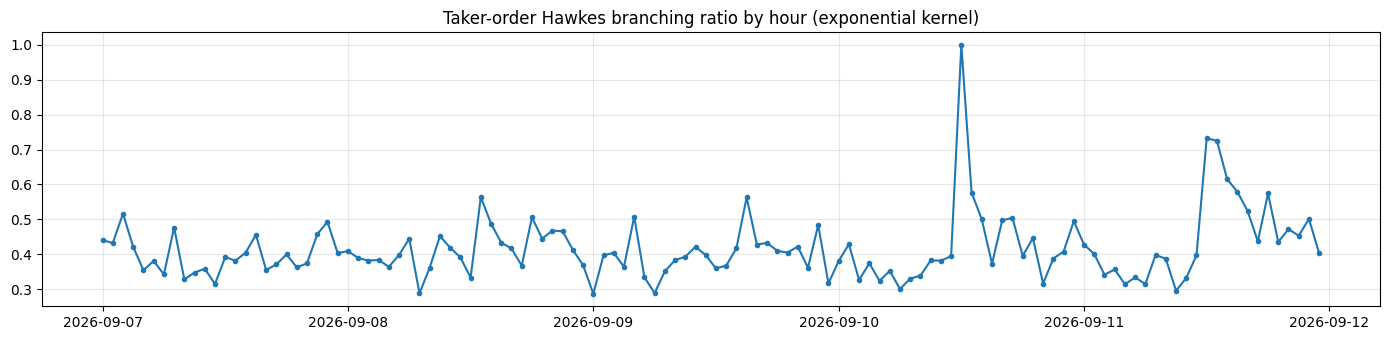

In [6]:
hr_rows = []; t0 = time.time()
for d in DEV:
    for hr in range(24):
        t, y = hour_events(d, hr, JITTER_SEEDS[0])
        if len(t) < 1000: continue
        f = best_exp(t, y, 3600.0)
        hr_rows.append(dict(date=d, hour=hr, n=len(t), beta=f['betas'][0], branching=f['branching'], mu_buy=f['mu'][0], mu_sell=f['mu'][1],
                            A_bb=f['A'][0, 0], A_bs=f['A'][0, 1], A_sb=f['A'][1, 0], A_ss=f['A'][1, 1]))
    print(f'{d}: hourly exponential fits ({time.time()-t0:.0f}s)')
hh = pd.DataFrame(hr_rows); hh['t'] = pd.to_datetime(hh.date) + pd.to_timedelta(hh.hour, unit='h')
m_, s_ = hh.branching.mean(), hh.branching.std(ddof=1); ci = (m_ - 1.96 * s_ / math.sqrt(len(hh)), m_ + 1.96 * s_ / math.sqrt(len(hh)))
print(f'branching ratio (exponential kernel, hourly): mean {m_:.3f} [95% CI {ci[0]:.3f}, {ci[1]:.3f}], median {hh.branching.median():.3f}, IQR {hh.branching.quantile(.25):.3f}–{hh.branching.quantile(.75):.3f}')
print('mean excitation matrix A (row = excited stream, column = source; buy, sell):'); print(hh[['A_bb', 'A_bs', 'A_sb', 'A_ss']].mean().round(3).to_dict())
print('decay rate chosen (s^-1):', hh.beta.value_counts().to_dict())
jit = []
for d in DEV:
    for hr in KERNEL_HOURS:
        for s in JITTER_SEEDS:
            t, y = hour_events(d, hr, s)
            if len(t) >= 1000: jit.append(dict(date=d, hour=hr, seed=s, branching=best_exp(t, y, 3600.0)['branching']))
jit = pd.DataFrame(jit); js = jit.groupby(['date', 'hour']).branching.agg(['mean', 'std'])
print(f'jitter sensitivity: mean across-seed std of the branching ratio = {js["std"].mean():.4f} (mean level {js["mean"].mean():.3f})')
fig, ax = plt.subplots(figsize=(14, 3.5)); ax.plot(hh.t, hh.branching, 'o-', ms=3); ax.set_title('Taker-order Hawkes branching ratio by hour (exponential kernel)'); ax.grid(alpha=.3)
plt.tight_layout(); fig.savefig(REP / '06_branching_by_hour.png', dpi=110); plt.show()
hh.to_csv(REP / '06_hawkes_hourly.csv', index=False); jit.to_csv(REP / '06_hawkes_jitter.csv', index=False)

## B2 · Six-stream Hawkes: taker orders, adds and cancels at the touch
Streams: 0 buy taker orders · 1 sell taker orders · 2 bid adds · 3 bid cancels · 4 ask adds · 5 ask cancels. An add or cancel is a batch whose touch price was unchanged and whose net limit-order change was N > 0 or N < 0 (notebook 03). **Batching:** book events within one ~27 ms batch share a timestamp, so they are **jittered uniformly within the batch interval** (T_prev, T]. Adds and cancels are net per batch, so their counts are lower bounds. A[i, j] is the expected number of stream-*i* events triggered by one stream-*j* event.

2026-09-07 06: 102,286 events, β=80.0, branching 0.358 (4s)
2026-09-07 14: 163,037 events, β=20.0, branching 0.629 (12s)
2026-09-08 06: 171,181 events, β=80.0, branching 0.459 (18s)
2026-09-08 14: 153,210 events, β=5.0, branching 1.000 (24s)
2026-09-09 06: 104,816 events, β=80.0, branching 0.351 (28s)
2026-09-09 14: 183,779 events, β=80.0, branching 0.504 (34s)
2026-09-10 06: 107,089 events, β=80.0, branching 0.369 (38s)
2026-09-10 14: 211,600 events, β=80.0, branching 0.517 (46s)
2026-09-11 06: 87,138 events, β=5.0, branching 0.986 (49s)
2026-09-11 14: 392,634 events, β=80.0, branching 0.643 (63s)
mean excitation matrix A[excited, source] over sampled hours:


,buy taker,sell taker,bid add,bid cancel,ask add,ask cancel
buy taker,0.438,0.049,0.028,0.006,0.011,0.037
sell taker,0.055,0.459,0.008,0.026,0.034,0.008
bid add,0.025,0.024,0.049,0.071,0.084,0.200
bid cancel,0.048,0.018,0.036,0.060,0.108,0.013
ask add,0.040,0.038,0.082,0.180,0.056,0.068
ask cancel,0.024,0.046,0.108,0.011,0.035,0.062


,effect,A,ci95
0,sell taker → bid cancel (adverse-selection fli...,0.0176,0.0121
1,sell taker → bid add (replenishment),0.0239,0.0216
2,buy taker → ask cancel (adverse-selection flight),0.0243,0.0115
3,buy taker → ask add (replenishment),0.0399,0.0379
4,buy taker → buy taker (herding/splitting),0.4377,0.0715
5,sell taker → sell taker,0.4594,0.0745
6,bid cancel → sell taker,0.0256,0.0117
7,ask cancel → buy taker,0.0369,0.0093


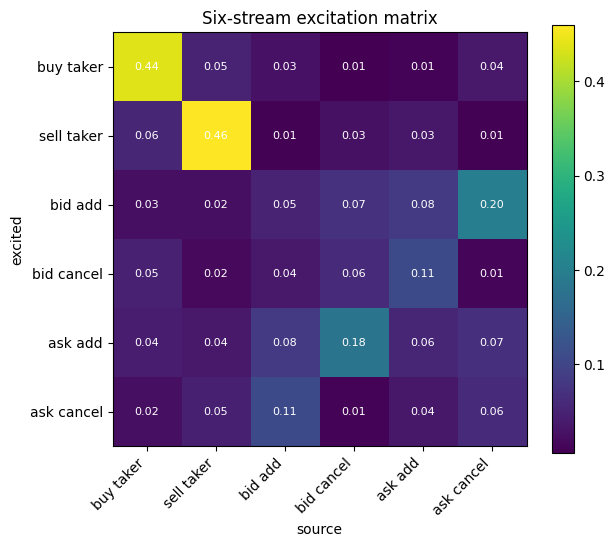

In [7]:
NAMES = ['buy taker', 'sell taker', 'bid add', 'bid cancel', 'ask add', 'ask cancel']
six = []; t0 = time.time()
for d in DEV:
    for hr in SIX_HOURS:
        evp = EVT / d / f'events_{d}_{hr:02d}.parquet'
        if not evp.exists(): continue
        ev = pd.read_parquet(evp, columns=['T', 'ok', 'mv_b', 'mv_a', 'N_b', 'N_a'])
        h0 = pd.Timestamp(d).value // 10**6 + hr * 3_600_000
        Tb = ev['T'].to_numpy(np.int64); Tprev = np.r_[Tb[0] - 27, Tb[:-1]]
        rng = np.random.default_rng(SEED + hr)
        ts, ty = [], []
        for code_, m in ((2, (ev.mv_b == 0) & (ev.N_b > 0)), (3, (ev.mv_b == 0) & (ev.N_b < 0)), (4, (ev.mv_a == 0) & (ev.N_a > 0)), (5, (ev.mv_a == 0) & (ev.N_a < 0))):
            m = (m & ev.ok).to_numpy()
            ts.append((Tprev[m] + rng.uniform(0, 1, m.sum()) * np.maximum(Tb[m] - Tprev[m], 1) - h0) / 1000.0); ty.append(np.full(m.sum(), code_))
        ot, oy = hour_events(d, hr, SEED); ts.append(ot); ty.append(oy)
        t = np.concatenate(ts); y = np.concatenate(ty).astype(np.int64); keep = (t >= 0) & (t < 3600); t, y = t[keep], y[keep]
        o = np.argsort(t, kind='stable'); t, y = t[o], y[o]
        f = max((ma_lib.hawkes_fit(t, y, 3600.0, [b], 6, EM_ITERS) for b in (5, 20, 80)), key=lambda f: f['ll'])
        six.append(dict(date=d, hour=hr, n=len(t), beta=f['betas'][0], branching=f['branching'], A=f['A']))
        print(f'{d} {hr:02d}: {len(t):,} events, β={f["betas"][0]}, branching {f["branching"]:.3f} ({time.time()-t0:.0f}s)')
Am = np.mean([s['A'] for s in six], axis=0); As = np.std([s['A'] for s in six], axis=0, ddof=1) / math.sqrt(len(six))
At = pd.DataFrame(Am, index=NAMES, columns=NAMES)
print('mean excitation matrix A[excited, source] over sampled hours:'); display(At.round(3))
read = pd.DataFrame([
    ('sell taker → bid cancel (adverse-selection flight)', 3, 1), ('sell taker → bid add (replenishment)', 2, 1),
    ('buy taker → ask cancel (adverse-selection flight)', 5, 0), ('buy taker → ask add (replenishment)', 4, 0),
    ('buy taker → buy taker (herding/splitting)', 0, 0), ('sell taker → sell taker', 1, 1),
    ('bid cancel → sell taker', 1, 3), ('ask cancel → buy taker', 0, 5)], columns=['effect', 'i', 'j'])
read['A'] = [Am[i, j] for i, j in zip(read.i, read.j)]; read['ci95'] = [1.96 * As[i, j] for i, j in zip(read.i, read.j)]
display(read[['effect', 'A', 'ci95']].round(4))
fig, ax = plt.subplots(figsize=(6.5, 5.5)); im = ax.imshow(Am, cmap='viridis'); ax.set_xticks(range(6)); ax.set_yticks(range(6))
ax.set_xticklabels(NAMES, rotation=45, ha='right'); ax.set_yticklabels(NAMES); ax.set_xlabel('source'); ax.set_ylabel('excited')
for i in range(6):
    for j in range(6): ax.text(j, i, f'{Am[i, j]:.2f}', ha='center', va='center', color='w', fontsize=8)
plt.colorbar(im); ax.set_title('Six-stream excitation matrix'); plt.tight_layout(); fig.savefig(REP / '06_six_stream.png', dpi=110); plt.show()
At.to_csv(REP / '06_six_stream_A.csv'); read.to_csv(REP / '06_six_stream_reading.csv', index=False)

## B3 · H7: do Hawkes intensities add predictive power beyond OFI?
For each fold, the buy/sell exponential Hawkes parameters are the **median of the hourly fits on that fold's training days** (decay = most common choice). The causal excitation part of each intensity is computed at every bucket end from past taker orders, giving two features: **net** (buy − sell) and **total** excitation.

**Timing convention (leak guard).** Each taker order is timestamped at the **end of the book batch it landed in**, the moment its effect becomes visible in the book, exactly like the feature grid. Raw trade times are up to one batch earlier than the book update they cause, so using them against a book-based target would let the features "see" part of the target. Model OFI1 + net + total is compared with OFI1 alone at the same horizons, with DM and Holm correction across horizons.

In [8]:
# Align each taker order to the END of the book batch it landed in (its effect is only visible in the book at that
# batch's transaction time). Using the raw trade time would give the trade stream a mechanical head start of up to one
# batch over the book-based target, which is a leak, not prediction. Same convention as the notebook 04 feature grid.
ORD_B = {}
for d in DEV:
    u_, T_ = [], []
    for hr in range(24):
        f = EVT / d / f'events_{d}_{hr:02d}.parquet'
        if f.exists():
            e = pd.read_parquet(f, columns=['u', 'T']); u_.append(e.u.to_numpy()); T_.append(e['T'].to_numpy())
    u_, T_ = np.concatenate(u_), np.concatenate(T_)
    o = pd.read_parquet(EVT / f'taker_orders_{d}.parquet', columns=['u_post', 'sign', 'usable']); o = o[o.usable]
    j = np.clip(np.searchsorted(u_, o.u_post.to_numpy()), 0, len(u_) - 1); ok = u_[j] == o.u_post.to_numpy()
    tb = T_[j][ok]; ty = (o.sign.to_numpy()[ok] < 0).astype(np.int64); oo = np.argsort(tb, kind='stable')
    ORD_B[d] = (tb[oo], ty[oo])
    print(f'{d}: {ok.mean():.4%} of usable taker orders mapped to their batch time')
h7 = []; t0 = time.time()
for h in H5_HORIZONS:
    k = max(1, int(round(h / BIN_S))); ys, e_base, e_aug = [], [], []
    for tr_days, te in FOLDS:
        hp = hh[hh.date.isin(tr_days)]; beta = float(hp.beta.mode().iloc[0])
        A = np.array([[hp.A_bb.median(), hp.A_bs.median()], [hp.A_sb.median(), hp.A_ss.median()]])
        def feats(d):
            b = ma_lib.bucket_levels(GRID[d], k); y = b.dp.shift(-1)
            m = (b.valid & b.valid.shift(-1, fill_value=False) & emb_mask(b.t_end, d)).to_numpy()
            tm, ty = ORD_B[d]; d0 = pd.Timestamp(d).value // 10**6          # batch-aligned order times
            Eg = ma_lib._hawkes_excitation_grid((tm - d0) / 1000.0, ty, (b.t_end.to_numpy() - d0) / 1000.0 + 1e-9, A, beta, 2)
            Z = np.c_[b.ofi1.to_numpy(), Eg[:, 0] - Eg[:, 1], Eg[:, 0] + Eg[:, 1]]
            return Z[m], y.to_numpy()[m]
        tr = [feats(d) for d in tr_days]; Ztr = np.vstack([z for z, _ in tr]); ytr = np.concatenate([y for _, y in tr]); Zte, yte = feats(te)
        cb = ols_fit(Ztr[:, :1], ytr); ca = ols_fit(Ztr, ytr)
        ys.append(yte); e_base.append((yte - ols_pred(cb, Zte[:, :1])) ** 2); e_aug.append((yte - ols_pred(ca, Zte)) ** 2)
    Y = np.concatenate(ys); Eb = np.concatenate(e_base); Ea = np.concatenate(e_aug)
    st, p, _ = ma_lib.dm_test(Eb, Ea, 6)
    h7.append(dict(h_s=h, r2_ofi1=1 - Eb.sum() / (Y ** 2).sum(), r2_ofi1_hawkes=1 - Ea.sum() / (Y ** 2).sum(), dm_stat=st, p=p))
    print(f'h={h}s done ({time.time()-t0:.0f}s)')
h7 = pd.DataFrame(h7); pv = h7.p.to_numpy(); o = np.argsort(pv); adj = np.empty_like(pv); run = 0.0
for r, i in enumerate(o): run = max(run, min(1.0, (len(pv) - r) * pv[i])); adj[i] = run
h7['p_holm'] = adj; h7['gain'] = h7.r2_ofi1_hawkes - h7.r2_ofi1
H7 = dict(supported=bool((h7.p_holm < 0.05).any()), horizons=[float(x) for x in h7.h_s[h7.p_holm < 0.05]])
display(h7.round(6)); print('H7:', H7); h7.to_csv(REP / '06_h7.csv', index=False)

2026-09-07: 100.0000% of usable taker orders mapped to their batch time
2026-09-08: 100.0000% of usable taker orders mapped to their batch time
2026-09-09: 100.0000% of usable taker orders mapped to their batch time
2026-09-10: 100.0000% of usable taker orders mapped to their batch time
2026-09-11: 99.9999% of usable taker orders mapped to their batch time
h=0.1s done (12s)
h=0.25s done (16s)
h=0.5s done (18s)
h=1.0s done (20s)
h=5.0s done (22s)
h=30.0s done (24s)


,h_s,r2_ofi1,r2_ofi1_hawkes,dm_stat,p,p_holm,gain
0,0.10,0.018271,0.024170,19.419602,0.000000,0.000000,0.005899
1,0.25,0.014180,0.019004,14.341535,0.000000,0.000000,0.004824
2,0.50,0.011966,0.013478,4.918003,0.000000,0.000002,0.001513
3,1.00,0.009190,0.010490,4.514173,0.000003,0.000010,0.001300
4,5.00,0.003152,0.003798,1.451518,0.073318,0.146636,0.000645
5,30.00,0.000718,-0.000581,-1.403059,0.919700,0.919700,-0.001299


H7: {'supported': True, 'horizons': [0.1, 0.25, 0.5, 1.0]}


In [9]:
hyp = pd.DataFrame([
    dict(hypothesis='H5', supported=H5['supported'], detail=f"winning candidates (beat OFI1 and microprice, Holm 5%): {H5['winning'] or 'none'}; levels kept by horizon: {H5['levels_kept']}"),
    dict(hypothesis='H7', supported=H7['supported'], detail=f"horizons with significant gain: {H7['horizons'] or 'none'}; max OOS R² gain {h7.gain.max():.6f}")])
display(hyp); hyp.to_csv(REP / '06_hypotheses.csv', index=False)
lines = ['# 06 · Multi-level OFI and Hawkes (development days)', '']
lines += [f"{r.hypothesis}: {'SUPPORTED' if r.supported else 'NOT SUPPORTED'} — {r.detail}" for r in hyp.itertuples()]
lines += ['', 'OOS R² (selected models):'] + [f"  h={h}s: micro {lad.loc['microprice', h]:.5f} | OFI1 {lad.loc['levels_1_1', h]:.5f} | L1-10 {lad.loc['levels_1_10', h]:.5f} | ridge {lad.loc['ridge', h]:.5f} | "
                                               f"integrated {lad.loc['integrated_pc1', h]:.5f} | OFI1+micro {lad.loc['ofi1_plus_micro', h]:.5f}" for h in H5_HORIZONS]
lines += ['', f"taker Hawkes: best kernel by held-out LL = {best_kernel}; hourly branching ratio mean {m_:.3f} [{ci[0]:.3f}, {ci[1]:.3f}] (upper bound: constant baseline per hour); jitter std {js['std'].mean():.4f}",
          'six-stream: ' + '; '.join(f"{r.effect}: {r.A:.3f}±{r.ci95:.3f}" for r in read.itertuples())]
(REP / '06_summary.md').write_text('\n'.join(lines), encoding='utf-8'); print('\n'.join(lines))
print('\nSend me: reports/06_summary.md, 06_hypotheses.csv, 06_h5_ladder.csv, 06_h5_dm.csv, 06_level_inclusion.csv, 06_hawkes_kernels.csv, '
      '06_hawkes_hourly.csv, 06_six_stream_A.csv, 06_six_stream_reading.csv, 06_h7.csv and the three PNGs')

,hypothesis,supported,detail
0,H5,False,"winning candidates (beat OFI1 and microprice, ..."
1,H7,True,"horizons with significant gain: [0.1, 0.25, 0...."


# 06 · Multi-level OFI and Hawkes (development days)

H5: NOT SUPPORTED — winning candidates (beat OFI1 and microprice, Holm 5%): none; levels kept by horizon: {0.1: 5, 0.25: 1, 0.5: 1, 1.0: 1, 5.0: 1, 30.0: 1}
H7: SUPPORTED — horizons with significant gain: [0.1, 0.25, 0.5, 1.0]; max OOS R² gain 0.005899

OOS R² (selected models):
  h=0.1s: micro 0.02477 | OFI1 0.01827 | L1-10 0.01983 | ridge 0.01983 | integrated 0.01490 | OFI1+micro 0.03428
  h=0.25s: micro 0.02914 | OFI1 0.01418 | L1-10 0.01432 | ridge 0.01431 | integrated 0.00888 | OFI1+micro 0.03411
  h=0.5s: micro 0.03380 | OFI1 0.01197 | L1-10 0.01186 | ridge 0.01185 | integrated 0.00661 | OFI1+micro 0.03600
  h=1.0s: micro 0.03600 | OFI1 0.00919 | L1-10 0.00916 | ridge 0.00919 | integrated 0.00595 | OFI1+micro 0.03655
  h=5.0s: micro 0.02527 | OFI1 0.00315 | L1-10 0.00281 | ridge 0.00247 | integrated 0.00180 | OFI1+micro 0.02519
  h=30.0s: micro 0.00520 | OFI1 0.00072 | L1-10 -0.00157 | ridge -0.00065 | integrated 0.00094 | OFI